# 3.05 — Comparación final de modelos, selección del `champion` y Model Registry

**Proyecto:** MiBici — TC5044.10 — Equipo 04
**Integración:** Leonardo Santos García
**Modelos:** José Eduardo De Moraes López (`PoissonRegressor`, 3.02), Erik Román Cortez (`RandomForestRegressor`, 3.03), José Emmanuel Vázquez Galán (`HistGradientBoostingRegressor`, 3.04)
**Fecha:** 7 de noviembre de 2026
**Rama:** `feat/phase2-final-comparison`

> **Problema de negocio:** Pronosticar viajes iniciados por estación y por hora para el día siguiente, con el objetivo de apoyar la planeación del rebalanceo de bicicletas.

Este notebook **no entrena modelos ni redefine reglas**: lee de MLflow las corridas que produjo `make train` desde un solo commit de `main` y presenta la comparación con las mismas funciones que usa `make compare` (`mibici/modeling/compare.py`). La elección del `champion` se toma con *validation* y las dos ventanas; *test* solo informa el desempeño final.

## 1. Objetivo y regla de selección

1. Verificar que las corridas oficiales de los cuatro modelos (baseline, Poisson, Random Forest y HGB) existan, vengan de un mismo commit y tengan el código confirmado.
2. Compararlas con la regla del contrato y elegir el `champion`.
3. Reportar la evaluación final en *test*, el Model Registry y un pronóstico de ejemplo.

| Elemento | Regla | Fuente |
|---|---|---|
| Candidato | Supera al baseline en WAPE en *validation*, junio **y** julio | 3.01, sección 7.6, regla 3 |
| Desempate | WAPE de *validation*, estabilidad entre ventanas, cohorte nueva y costo | 3.01, sección 7.6, regla 4; plan del sábado |
| Volumen pronosticado ÷ real | Diagnóstico para la decisión; **no** es regla de candidato | Decisión del equipo, 7 de noviembre de 2026 |
| *Test* | Una sola evaluación por modelo, después de elegir; no participa en la elección | 3.01, sección 7.3 |

In [1]:
# Libraries: figures, MLflow client and tables
import matplotlib.pyplot as plt
import mlflow
import pandas as pd

# Shared settings of the project (mibici/config.py)
from mibici.config import (
    CHAMPION_ALIAS,
    FIGURES_DIR,
    MLFLOW_TRACKING_URI,
    PREDICTIONS_DIR,
    REGISTERED_MODEL_NAME,
    REPORTS_DIR,
)

# Same functions that `make compare` uses, so the table here is identical by construction
from mibici.modeling.compare import PERIODS, comparison_table, load_runs, official_runs

# Health check of the local MLflow server
from mibici.tracking import check_tracking_server

# Commit of main of the comparison runs: validation, June and July (merge of PR #15)
INTEGRATION_COMMIT = "05d4ac6"
# Commit of main of the test runs and the registered versions (merge of PR #17). Between
# both commits only the way models are saved (PR #16) and one test (PR #17) changed
TEST_COMMIT = "9e0a723"
# Order in which models appear in tables and figures
MODEL_ORDER = ["baseline", "poisson", "random_forest", "hgb"]

# Copies of what is read from MLflow, so the notebook also runs without the local server
MODELING_REPORTS = REPORTS_DIR / "modeling"
MODELING_REPORTS.mkdir(parents=True, exist_ok=True)
OFFICIAL_RUNS_CSV = MODELING_REPORTS / "3.05-official-runs.csv"
TEST_RUNS_CSV = MODELING_REPORTS / "3.05-test-runs.csv"
REGISTRY_CSV = MODELING_REPORTS / "3.05-registry.csv"
# Folder for the saved figures
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Columns the comparison needs from each MLflow run
RUN_COLUMNS = [
    "params.model",
    "params.mode",
    "tags.mlflow.runName",
    "tags.git_commit",
    "tags.git_dirty",
    "start_time",
]


def server_available() -> bool:
    """True if the MLflow Tracking Server answers (`make mlflow`)."""
    # check_tracking_server raises RuntimeError when the server is down
    try:
        check_tracking_server()
        return True
    except RuntimeError:
        return False


def keep_columns(runs: pd.DataFrame) -> pd.DataFrame:
    """Identification columns plus every metric of the runs."""
    # Every metric column logged by make train (model, baseline, volume, time)
    metrics = [column for column in runs.columns if column.startswith("metrics.")]
    return runs[RUN_COLUMNS + metrics]


# Decide once whether to read from MLflow or from the saved CSV copies
MLFLOW_ONLINE = server_available()
print("MLflow disponible:", MLFLOW_ONLINE)

/home/watson/miniforge3/envs/mibici/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-07 18:13:30.613 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /home/watson/projects/mibici


MLflow disponible: True


## 2. Corridas oficiales

Se toman de MLflow las corridas de *validation*, junio y julio del commit de integración, con `official_runs` de `compare.py`: la más reciente de cada modelo y modo, solo con código confirmado (`git_dirty=false`). Si el servidor no está disponible, se usa la copia en `reports/modeling/3.05-official-runs.csv`.

In [2]:
# Official runs: from MLflow when available (and saved as CSV), otherwise from the saved CSV
if MLFLOW_ONLINE:
    # Latest clean run of every model in validation, June and July of that commit
    official = keep_columns(official_runs(load_runs(), commit=INTEGRATION_COMMIT))
    # Keep a copy so the notebook can be re-run without the server
    official.to_csv(OFFICIAL_RUNS_CSV, index=False)
else:
    # No server: read the copy saved the last time the notebook ran with MLflow
    official = pd.read_csv(
        OFFICIAL_RUNS_CSV, parse_dates=["start_time"], dtype={"tags.git_dirty": str}
    )

# One run per model and mode, all from the integration commit and with committed code
assert len(official) == len(MODEL_ORDER) * len(PERIODS), "Run make train for every model and mode"
# The four models are present
assert set(official["params.model"]) == set(MODEL_ORDER)
# Every run comes from the integration commit
assert official["tags.git_commit"].str.startswith(INTEGRATION_COMMIT).all()
# ...and from committed code (no local changes when it ran)
assert official["tags.git_dirty"].eq("false").all()

# Run name of each model (rows) and evaluation mode (columns)
official.pivot(index="params.model", columns="params.mode", values="tags.mlflow.runName").loc[
    MODEL_ORDER, list(PERIODS)
]

params.mode,validation,window_june,window_july
params.model,,,
baseline,baseline-validation-01,baseline-window_june-01,baseline-window_july-01
poisson,poisson-validation-01,poisson-window_june-01,poisson-window_july-01
random_forest,random_forest-validation-01,random_forest-window_june-01,random_forest-window_july-01
hgb,hgb-validation-01,hgb-window_june-01,hgb-window_july-01


## 3. Tabla comparativa

`comparison_table` es la misma función que usa `make compare`: WAPE y MAE en cada periodo, si el modelo supera al baseline **en las mismas filas** de cada corrida, si es candidato, y los diagnósticos de la cohorte nueva, el volumen y el tiempo de entrenamiento (en *validation*).

In [3]:
# One row per model: scores by period, baseline comparison and candidate rule
comparison = comparison_table(official)

# Main view: WAPE by period, baseline comparison and candidate status
columns = [
    "validation_wape",
    "june_wape",
    "july_wape",
    "beats_baseline_validation",
    "beats_baseline_june",
    "beats_baseline_july",
    "candidate",
]
# Show those columns with four decimals
comparison[columns].style.format(precision=4)

,validation_wape,june_wape,july_wape,beats_baseline_validation,beats_baseline_june,beats_baseline_july,candidate
model,,,,,,,
hgb,0.6574,0.6858,0.6323,True,True,True,True
random_forest,0.6901,0.7169,0.6657,True,True,True,True
baseline,0.6964,0.7227,0.6724,False,False,False,False
poisson,0.7039,0.7317,0.6792,False,False,False,False


In [4]:
# Diagnostics in validation: MAE, 2026 cohort, forecast volume and cost
diagnostics = [
    "validation_mae",
    "new_cohort_wape",
    "volume_ratio",
    "new_cohort_volume_ratio",
    "fit_seconds",
    "git_commit",
]
# Show those columns with three decimals
comparison[diagnostics].style.format(precision=3)

,validation_mae,new_cohort_wape,volume_ratio,new_cohort_volume_ratio,fit_seconds,git_commit
model,,,,,,
hgb,0.913,0.956,0.794,0.592,43.484,05d4ac6
random_forest,0.958,1.111,0.828,0.833,11.033,05d4ac6
baseline,0.967,1.104,0.983,0.965,0.152,05d4ac6
poisson,0.978,1.087,0.989,0.826,10.358,05d4ac6


## 4. Visualización

Cada panel muestra el WAPE de los modelos en un periodo; la línea punteada es el baseline del mismo periodo. La segunda figura muestra cuántas bicicletas pronostica cada modelo frente a las que salieron (1.0 = volumen correcto).

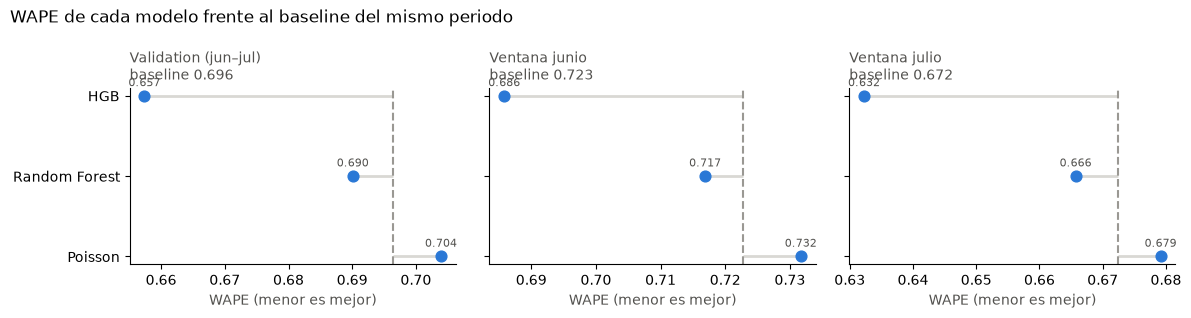

In [5]:
SERIES, MUTED, BASELINE_INK = "#2a78d6", "#52514e", "#9a9893"  # colors of notebooks 3.01 and 3.03
# Display names of the models in the figures
LABELS = {
    "baseline": "Baseline",
    "poisson": "Poisson",
    "random_forest": "Random Forest",
    "hgb": "HGB",
}
# The baseline is drawn as a reference line, not as a row
models = [model for model in MODEL_ORDER if model != "baseline"]
# Vertical position of each model
y = range(len(models))

# WAPE by period: one panel per period, models as rows, baseline as a dashed reference
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, (label, title) in zip(
    axes,
    [("validation", "Validation (jun–jul)"), ("june", "Ventana junio"), ("july", "Ventana julio")],
):
    # WAPE of each model and of the baseline in this period
    values = comparison.loc[models, f"{label}_wape"]
    baseline_wape = comparison.loc["baseline", f"{label}_wape"]
    # Gray segment from the baseline to each model, the dot marks the model
    ax.hlines(y, baseline_wape, values, color="#d9d8d4", linewidth=2)
    ax.scatter(values, y, color=SERIES, s=60, zorder=3)
    # Dashed line: baseline of the same period
    ax.axvline(baseline_wape, color=BASELINE_INK, linestyle="--", linewidth=1.5)
    # Value label above each dot
    for yi, value in zip(y, values):
        ax.annotate(
            f"{value:.3f}",
            (value, yi),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            color=MUTED,
        )
    # Panel title, axis label and lighter frame
    ax.set_title(f"{title}\nbaseline {baseline_wape:.3f}", fontsize=10, color=MUTED, loc="left")
    ax.set_xlabel("WAPE (menor es mejor)", color=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
# Model names only on the first panel (the panels share the vertical axis)
axes[0].set_yticks(list(y), [LABELS[model] for model in models])
fig.suptitle("WAPE de cada modelo frente al baseline del mismo periodo", x=0.01, ha="left")
fig.tight_layout()
# Save the figure for the report, then show it
fig.savefig(FIGURES_DIR / "3.05-wape-by-period.png", bbox_inches="tight")
plt.show()

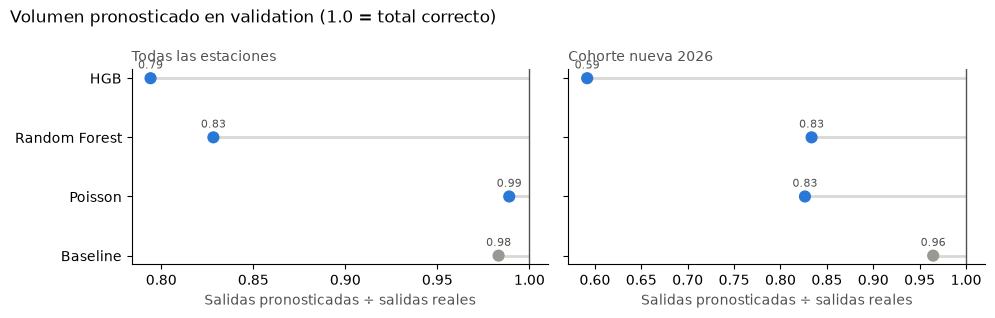

In [6]:
# Forecast volume in validation: all rows and the 2026 cohort (1.0 = right total)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (column, title) in zip(
    axes,
    [("volume_ratio", "Todas las estaciones"), ("new_cohort_volume_ratio", "Cohorte nueva 2026")],
):
    # Volume ratio of every model, the baseline included
    values = comparison.loc[MODEL_ORDER, column]
    rows = range(len(MODEL_ORDER))
    # Gray segment from the right total (1.0) to each model
    ax.hlines(rows, 1.0, values, color="#d9d8d4", linewidth=2)
    # Baseline in gray, team models in blue
    ax.scatter(
        values,
        rows,
        color=[BASELINE_INK if m == "baseline" else SERIES for m in MODEL_ORDER],
        s=60,
        zorder=3,
    )
    # Vertical line: forecast total equal to the observed total
    ax.axvline(1.0, color=MUTED, linewidth=1)
    # Value label above each dot
    for row, value in zip(rows, values):
        ax.annotate(
            f"{value:.2f}",
            (value, row),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            color=MUTED,
        )
    # Panel title, axis label and lighter frame
    ax.set_title(title, fontsize=10, color=MUTED, loc="left")
    ax.set_xlabel("Salidas pronosticadas ÷ salidas reales", color=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
# Model names only on the first panel (shared vertical axis)
axes[0].set_yticks(list(range(len(MODEL_ORDER))), [LABELS[m] for m in MODEL_ORDER])
fig.suptitle("Volumen pronosticado en validation (1.0 = total correcto)", x=0.01, ha="left")
fig.tight_layout()
# Save the figure for the report, then show it
fig.savefig(FIGURES_DIR / "3.05-forecast-volume.png", bbox_inches="tight")
plt.show()

## 5. Decisión: `champion`

**Candidatos** (sección 3): HGB y Random Forest. Poisson y el baseline no son candidatos.

| Criterio de desempate (3.01, sección 7.6) | HGB | Random Forest | Gana |
|---|---|---|---|
| 1. WAPE de *validation* | 0.657 | 0.690 | HGB |
| 2. Estabilidad: WAPE en junio y julio | 0.686 y 0.632 | 0.717 y 0.666 | HGB, en las dos ventanas |
| 3. Cohorte nueva 2026 (WAPE) | 0.956 (mejora al baseline: 1.104) | 1.111 (peor que el baseline) | HGB |
| 4. Costo de entrenamiento | 43 s | 11 s | Random Forest (diferencia sin efecto práctico) |
| Diagnóstico: volumen pronosticado ÷ real | 0.79 (cohorte nueva 0.59) | 0.83 (cohorte nueva 0.83) | Random Forest |

| Elemento | Contenido |
|---|---|
| **Decisión** | **`champion` = HGB** (`HistGradientBoostingRegressor`, `loss="absolute_error"`, José Emmanuel Vázquez Galán), tomada por el integrador (Leonardo Santos García) con *validation* y las dos ventanas, antes de evaluar *test* |
| **Evidencia** | Secciones 3 y 4: es candidato y gana en los tres primeros criterios de desempate del contrato con un margen estable (≈ 5 % menos WAPE que el baseline en los tres periodos). Además supera al baseline multiplicado por 0.8 (WAPE 0.678, diagnóstico de la libreta 3.02, sección 8.4), así que su ventaja no se explica solo por pronosticar menos |
| **Justificación** | Las reglas de selección se fijaron el miércoles, antes de ver los resultados, y se aplican sin cambios. HGB es el modelo con menor error por estación y hora, que es lo que mide el contrato, y el único que mejora las estaciones de la expansión de 2026 |
| **Limitación** | HGB pronostica **≈ 21 % menos salidas en total** que las observadas (0.79) y **≈ 41 % menos en las estaciones nuevas** (0.59). `absolute_error` aprende la mediana, y con ≈ 49 % de horas en cero la mediana queda por debajo de la media. Para dimensionar flota o personal con totales, el pronóstico subestima la demanda, sobre todo en las estaciones nuevas |
| **Área de mejora (Fase 3)** | Calibrar el total con un factor estimado **solo con *train*** (por segmento: estaciones consolidadas y nuevas) y agregar al contrato, **antes** de la siguiente comparación, una regla de volumen pronosticado. No se agrega ahora porque cambiaría las reglas después de ver los resultados |
| **Implementación** | `make train MODEL=<modelo> MODE=test FINAL=1 REGISTER=1` para Poisson, Random Forest y HGB (sección 6) y `make champion VERSION=3 CHAMPION_ARGS="--commit 05d4ac6"` (sección 7) |

## 6. Evaluación final en *test*

Cada modelo se entrenó con *train* + *validation* (2022-01-08 → 2026-07-31) y se evaluó **una sola vez** en *test* (agosto–septiembre de 2026), con `make train MODEL=<modelo> MODE=test FINAL=1 REGISTER=1`. Estos resultados **no cambian la elección** de la sección 5, que se tomó antes con *validation* y las ventanas: solo informan el desempeño esperado.

**Dos intentos, mismas métricas.**

| Intento | Commit | Resultado |
|---|---|---|
| 1 | `05d4ac6` | Las tres corridas (`poisson-test-01`, `random_forest-test-01`, `hgb-test-01`) entrenaron y evaluaron, pero **fallaron al guardar el modelo**: MLflow 3.17 guarda los modelos de scikit-learn con *skops*, que rechaza tipos que no conoce (`NonNegativeRegressor`, el preprocesamiento de Poisson, los árboles de scikit-learn). Quedaron en MLflow con estado `FAILED` y sin versión registrada |
| 2 | `9e0a723` | Corrección en el PR #16 (guardar con *cloudpickle* y una prueba que guarda y carga los cuatro bloques) y en el PR #17 (avisos de esa prueba). Las tres corridas terminaron y se registraron como versiones 1 (Poisson), 2 (Random Forest) y 3 (HGB) |

Entre los dos commits no cambió cómo se entrena ni cómo se evalúa: las métricas de *test* de ambos intentos son **idénticas** (misma semilla, mismos datos). La tabla y la figura usan el intento 2 (`TEST_COMMIT`).

In [7]:
# Test runs of TEST_COMMIT: latest clean, finished run of each model
if MLFLOW_ONLINE:
    # Every finished run of the modeling experiment
    runs = load_runs()
    # Test runs of the test commit with committed code
    is_test = (
        runs["params.mode"].eq("test")
        & runs["tags.git_commit"].str.startswith(TEST_COMMIT)
        & runs["tags.git_dirty"].eq("false")
    )
    # Latest of those runs for each model
    test_runs = keep_columns(
        runs[is_test].sort_values("start_time").groupby("params.model").tail(1)
    )
    # Keep a copy so the notebook can be re-run without the server
    test_runs.to_csv(TEST_RUNS_CSV, index=False)
else:
    # No server: read the saved copy
    test_runs = pd.read_csv(
        TEST_RUNS_CSV, parse_dates=["start_time"], dtype={"tags.git_dirty": str}
    )

# One row per model with the test metrics of the model and of the baseline
test_table = test_runs.set_index("params.model").rename_axis("model")
test_table = pd.DataFrame(
    {
        "test_wape": test_table["metrics.all_wape"],
        "baseline_test_wape": test_table["metrics.baseline_all_wape"],
        "test_mae": test_table["metrics.all_mae"],
        "new_cohort_wape": test_table["metrics.new_station_cohort_wape"],
        "baseline_new_cohort_wape": test_table["metrics.baseline_new_station_cohort_wape"],
        "volume_ratio": test_table["metrics.all_volume_ratio"],
        "baseline_volume_ratio": test_table["metrics.baseline_all_volume_ratio"],
    }
)
# Reported only: test does not change the choice of section 5
test_table["beats_baseline_test"] = test_table["test_wape"] < test_table["baseline_test_wape"]
# Show the models in the usual order with four decimals
test_table.loc[[m for m in MODEL_ORDER if m in test_table.index]].style.format(precision=4)

,test_wape,baseline_test_wape,test_mae,new_cohort_wape,baseline_new_cohort_wape,volume_ratio,baseline_volume_ratio,beats_baseline_test
model,,,,,,,,
poisson,0.6433,0.6227,0.9602,0.9929,0.9409,0.9582,0.8956,False
random_forest,0.6417,0.6227,0.9578,0.9939,0.9409,0.7567,0.8956,False
hgb,0.6066,0.6227,0.9053,0.8525,0.9409,0.7195,0.8956,True


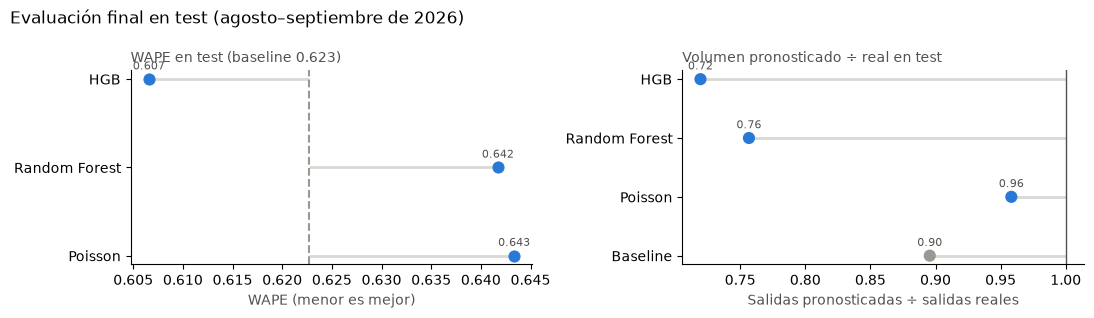

In [8]:
# Test results: WAPE against the baseline and forecast volume (1.0 = right total)
# Team models with a test run, in the usual order
test_models = [model for model in MODEL_ORDER if model in test_table.index]
baseline_test_wape = test_table["baseline_test_wape"].iloc[0]  # same rows for every model
# Every run scored the baseline on the same test rows, so it must be identical
assert test_table["baseline_test_wape"].eq(baseline_test_wape).all()

# Left panel: WAPE in test against the baseline
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2))
rows = range(len(test_models))
values = test_table.loc[test_models, "test_wape"]
# Gray segment from the baseline to each model, the dot marks the model
ax1.hlines(rows, baseline_test_wape, values, color="#d9d8d4", linewidth=2)
ax1.scatter(values, rows, color=SERIES, s=60, zorder=3)
# Dashed line: baseline in test
ax1.axvline(baseline_test_wape, color=BASELINE_INK, linestyle="--", linewidth=1.5)
# Value label above each dot
for row, value in zip(rows, values):
    ax1.annotate(
        f"{value:.3f}",
        (value, row),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color=MUTED,
    )
# Model names, panel title and axis label
ax1.set_yticks(list(rows), [LABELS[model] for model in test_models])
ax1.set_title(
    f"WAPE en test (baseline {baseline_test_wape:.3f})", fontsize=10, color=MUTED, loc="left"
)
ax1.set_xlabel("WAPE (menor es mejor)", color=MUTED)

# Volume: the baseline first (from any run, same rows), then each model
volume = pd.Series(
    {"baseline": test_table["baseline_volume_ratio"].iloc[0]}
    | test_table.loc[test_models, "volume_ratio"].to_dict()
)
rows = range(len(volume))
# Right panel: gray segment from the right total (1.0) to each model
ax2.hlines(rows, 1.0, volume.values, color="#d9d8d4", linewidth=2)
ax2.scatter(
    volume.values,
    rows,
    s=60,
    zorder=3,
    color=[BASELINE_INK if model == "baseline" else SERIES for model in volume.index],
)
# Vertical line: forecast total equal to the observed total
ax2.axvline(1.0, color=MUTED, linewidth=1)
# Value label above each dot
for row, value in zip(rows, volume.values):
    ax2.annotate(
        f"{value:.2f}",
        (value, row),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color=MUTED,
    )
# Model names, panel title and axis label
ax2.set_yticks(list(rows), [LABELS[model] for model in volume.index])
ax2.set_title("Volumen pronosticado ÷ real en test", fontsize=10, color=MUTED, loc="left")
ax2.set_xlabel("Salidas pronosticadas ÷ salidas reales", color=MUTED)
# Lighter frame on both panels
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Evaluación final en test (agosto–septiembre de 2026)", x=0.01, ha="left")
fig.tight_layout()
# Save the figure for the report, then show it
fig.savefig(FIGURES_DIR / "3.05-test-results.png", bbox_inches="tight")
plt.show()

## 7. Model Registry

Cada modelo quedó registrado como una versión de `mibici-departures`, con las etiquetas `model`, `owner` y `git_commit`. El alias `champion` se asignó con `make champion VERSION=<n>`, que solo lo permite si el modelo es candidato en la sección 3.

In [9]:
# Registered versions and the version that holds the champion alias
if MLFLOW_ONLINE:
    # Connect to the local MLflow server
    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    client = mlflow.MlflowClient()
    # Version that holds the champion alias (set with make champion)
    champion = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, CHAMPION_ALIAS).version
    # One row per registered version, with the tags written by make train
    registry = pd.DataFrame(
        [
            {
                "version": int(version.version),
                "model": version.tags.get("model"),
                "owner": version.tags.get("owner"),
                "git_commit": version.tags.get("git_commit", "")[:7],
                "run_id": version.run_id,
                "champion": version.version == champion,
            }
            for version in client.search_model_versions(f"name = '{REGISTERED_MODEL_NAME}'")
        ]
    ).sort_values("version")
    # Keep a copy so the notebook can be re-run without the server
    registry.to_csv(REGISTRY_CSV, index=False)
else:
    # No server: read the saved copy
    registry = pd.read_csv(REGISTRY_CSV)

# Which version is the champion, then the full table
print(
    f"{REGISTERED_MODEL_NAME}@{CHAMPION_ALIAS} → versión "
    f"{registry.loc[registry['champion'], 'version'].item()}"
)
registry

mibici-departures@champion → versión 3


,version,model,owner,git_commit,run_id,champion
2,1,poisson,José Eduardo De Moraes López,9e0a723,2a4d0a20e6da478693831a9f89c5b232,False
1,2,random_forest,Erik Román Cortez,9e0a723,87cfba8be0fe4a0aaa6bac6e7577b078,False
0,3,hgb,José Emmanuel Vázquez Galán,9e0a723,3a0e96c6c8c14ec5a8755d675634b1ee,True


## 8. Pronóstico de ejemplo

`make predict DATE=2026-09-30` carga `mibici-departures@champion` y pronostica todas las estaciones y horas de servicio de ese día. El archivo no se versiona (se regenera desde el modelo registrado).

In [10]:
# Forecast of one day written by make predict (regenerated from the registered model)
forecast_path = PREDICTIONS_DIR / "predictions_2026-09-30.csv"
if forecast_path.exists():
    # One row per station and service hour of the day
    forecast = pd.read_csv(forecast_path, parse_dates=["hour_start"])
    # Size of the forecast and total departures forecast for the day
    print(
        f"{len(forecast):,} pronósticos · {forecast['station_id'].nunique()} estaciones · "
        f"{forecast['predicted_departures'].sum():,.0f} salidas pronosticadas en el día"
    )
    # First rows as an example
    display(forecast.head(10))
else:
    # The file is not versioned: it is regenerated with make predict
    print(f"No existe {forecast_path.name}: ejecuta make predict DATE=2026-09-30")

9,340 pronósticos · 467 estaciones · 11,796 salidas pronosticadas en el día


,station_id,hour_start,predicted_departures
0,2,2026-09-30 00:00:00,0.000003
1,2,2026-09-30 05:00:00,0.000003
2,2,2026-09-30 06:00:00,2.000000
3,2,2026-09-30 07:00:00,3.017579
4,2,2026-09-30 08:00:00,5.104376
5,2,2026-09-30 09:00:00,2.409592
6,2,2026-09-30 10:00:00,3.977122
7,2,2026-09-30 11:00:00,1.999997
8,2,2026-09-30 12:00:00,3.317031
9,2,2026-09-30 13:00:00,2.409592


## 9. Conclusiones

### 9.1 Resultados

1. **HGB es el `champion`.** Es candidato (supera al baseline en *validation*, junio y julio) y gana los tres primeros criterios de desempate del contrato: WAPE de *validation* (0.657 frente a 0.690 de Random Forest), las dos ventanas y la cohorte nueva (secciones 3–5).
2. ***Test* confirma la elección.** HGB es el **único** modelo que supera al baseline en agosto–septiembre de 2026: WAPE 0.607 frente a 0.623 (sección 6).
3. **La ventaja se reduce fuera de muestra:** de ≈ 5.6 % menos WAPE que el baseline en *validation* a ≈ 2.6 % en *test*. En *test*, ≈ 18 % de las filas son de estaciones sin filas en *train* (3.01, sección 4.2), el escenario más difícil para todos los modelos.
4. **El sesgo de volumen de HGB crece:** pronostica el 79 % de las salidas reales en *validation*, el 72 % en *test* y el 57 % el 30 de septiembre de 2026 (11,796 frente a 20,858; sección 8). Es la limitación principal del `champion` para planear con totales.
5. **Random Forest** fue candidato en *validation*, pero en *test* no supera al baseline (0.642 frente a 0.623). Su ventaja en *validation* se explicaba sobre todo por pronosticar menos: el baseline multiplicado por 0.8 obtiene 0.678 en *validation*, mejor que Random Forest (3.02, sección 8.4).
6. **Poisson** no es candidato (≈ 1 % peor que el baseline en todos los periodos), pero es el único modelo calibrado en volumen: 0.99 en *validation* y 0.96 en *test*.

### 9.2 Áreas de mejora (Fase 3)

1. **Calibrar el volumen** del `champion` con un factor estimado **solo con *train***, por segmento (estaciones consolidadas y nuevas), y evaluarlo con las mismas reglas.
2. **Agregar al contrato una regla de volumen pronosticado** antes de la siguiente comparación, para que el criterio de selección refleje también la planeación con totales.
3. **Features con información distinta de `avg_4_weeks`**, que domina a los tres modelos: ubicación de la estación, clima, festivos y vacaciones (propuestas de las libretas 3.02 y 3.03).
4. **Tratamiento específico para estaciones nuevas**, el segmento con mayor error y mayor subpronóstico.
5. **Pronóstico de días futuros:** `make predict` solo pronostica días presentes en `processed_v1`; para operar hace falta construir las filas de las estaciones activas del día siguiente.
6. **Mejoras técnicas:** ampliar `make lint` a libretas y pruebas, y eliminar los avisos de MLflow al describir el dataset (`mibici/tracking.py`).

### 9.3 Roles e interacción del equipo

Los roles se entienden como responsabilidades del ciclo MLOps y no como puestos exclusivos. Una persona puede participar en varias funciones.

| Rol | Etapa MLOps | Responsables y actividades | Evidencia e interacción |
|---|---|---|---|
| Data Engineer | Datos y features para modelado | Leonardo: features de historia de la estación (`avg_4_weeks`, `t_168` con sus respaldos) y partición temporal sobre `processed_v1` | `mibici/features.py` y `mibici/modeling/splits.py` (PR #10); los tres modelos entrenan sobre la misma tabla |
| Data Scientist | Experimentación, diagnóstico y selección de modelos | José Eduardo: preprocesamiento de Poisson y diagnóstico media frente a mediana; Erik: grids de Random Forest, diagnóstico del sesgo y corrección con `log1p`; José Emmanuel: comparación de pérdidas y ajuste de HGB; Leonardo: contrato de modelado y selección del `champion` | Notebooks 3.01–3.05; los diagnósticos de Erik y José Eduardo explican el sesgo de volumen que se usa en la decisión (sección 5) |
| ML Engineer | Entrenamiento, *tracking* y registro de modelos | José Eduardo, Erik y José Emmanuel: bloque de su modelo en `models.py` y corridas con `make train`; Leonardo: entrenamiento por CLI con MLflow, comparación, Model Registry, alias `champion` y pronóstico | PR #11, #12 y #13; corridas del experimento `mibici-modeling`; `mibici-departures` v1–v3 con `champion` en la v3 (sección 7) |
| Software Engineer | Código modular, pruebas y revisión | Leonardo: base común en `mibici/`, 110 pruebas, lint, revisión de los tres PR y resolución del conflicto de imports; Erik: ajuste de la prueba de la semilla común para estimadores envueltos | PR #10, #15, #16 y #17; la revisión de los PR del equipo se hizo antes de cada merge |
| SRE / reproducibilidad | Cómputo y reproducción de resultados | Leonardo: reproducción en la DGX de los tres modelos desde commits limpios (`git_dirty=false`); Erik: dimensionamiento de tiempo y memoria de Random Forest; José Eduardo: dependencia `ipywidgets` en `environment.yml` | Las métricas de los tres modelos se reprodujeron idénticas en otra máquina; corridas oficiales de un solo commit (secciones 2 y 6) |

Flujo: el integrador liberó la base común → cada integrante ajustó su modelo en su rama y lo entregó por PR → el integrador revisó, reprodujo y comparó los tres modelos bajo el mismo contrato → registro en el Model Registry y alias `champion`.

## Declaración de uso de inteligencia artificial

En la elaboración de este notebook se utilizaron las siguientes herramientas de IA:

- Anthropic. (2026). *Claude Opus 5.5* [Modelo de lenguaje grande], mediante Claude Code (extensión de VS Code). Utilizado para **generación de código** (lectura de corridas de MLflow, tabla comparativa, figuras, evaluación en *test*, Model Registry y pronóstico), para las **herramientas de integración** de `mibici/` (comparación, registro, `champion` y pronóstico), para la **revisión y reproducción** de los PR del equipo, para la **verificación de resultados** (ejecución completa del notebook, pruebas y Ruff) y para la **redacción preliminar** de las interpretaciones, la tabla de decisión y las conclusiones. https://claude.com/claude-code
- OpenAI. (2026). *ChatGPT (basado en GPT Sol 5.6)* [Modelo de lenguaje grande]. Utilizado para **planeación del trabajo** y **definición de las tareas** de la integración. https://chat.openai.com/

Las decisiones de este notebook (corridas oficiales, elección del `champion`, registro de los modelos y áreas de mejora) fueron tomadas y aprobadas por el integrador (Leonardo Santos García) a partir de la evidencia mostrada en cada sección. Todo el contenido generado fue revisado, ejecutado y validado por el integrador; el equipo asume la responsabilidad final de lo entregado.